LLMS Text Generation 

In [1]:
##pip install transformers == 4.56.1 torch == 2.8.0+cu126
##pip install huggingface-hub == 0.35.0 datasets == 4.0.0

In [4]:
!pip install pandas



[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
!pip install seaborn tabulate



[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Install

    Load the required Libaries 

In [6]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings('ignore')

from transformers import pipeline, GPT2LMHeadModel, GPT2Tokenizer
import torch
import gzip, json, random, time
import seaborn as sns
from tabulate import tabulate


E1 Load a Generative AI Model 

In [7]:
# Global variable to store AI models
ai_models = {}
def setup_ai_models():
    """Setup available AI models"""
    global ai_models

    print("Loading AI models for demonstration...")
    ai_models['text_generator'] = pipeline(
                "text-generation",
                model="gpt2",
                max_length=100
                )

    ai_models['sentiment'] = pipeline(
                "sentiment-analysis",
                model="distilbert-base-uncased-finetuned-sst-2-english"
                )

    ai_models['classifier'] = pipeline(
                "zero-shot-classification",
                model="facebook/bart-large-mnli"
                )

    print("✅ Models loaded successfully!")
    return ai_models



In [8]:
# Setup models and run demos
ai_models = setup_ai_models()

Loading AI models for demonstration...


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

[transformers] Passing `generation_config` together with generation-related arguments=({'max_length'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/515 [00:00<?, ?it/s]

✅ Models loaded successfully!


E2 First Experiment with Text Generation

In [9]:
def demonstrate_text_generation():
        """Show how AI generates text"""
        print("\nTEXT GENERATION DEMO")
        print("-" * 50)
        prompts = [
            "The future of artificial intelligence",
            "Best practices for online shopping",
            "Benefits of using AI in business"
        ]

        if 'text_generator' in ai_models:
            for prompt in prompts:
                try:
                    result = ai_models['text_generator'](
                        prompt,
                        max_length=60,
                        num_return_sequences=1,
                        temperature=0.7
                    )
                    generated = result[0]['generated_text']
                    print(f"Prompt: {prompt}")
                    print("AI Response:")
                    print(generated)
                    print("-" * 50)
                except Exception as e:
                    print(f"Error with prompt: {prompt}")
                    print(f"Details: {e}")
                    print("-" * 50)

# run the demo

demonstrate_text_generation()

[transformers] Passing `generation_config` together with generation-related arguments=({'temperature', 'max_length', 'num_return_sequences'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.



TEXT GENERATION DEMO
--------------------------------------------------


[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer GPT2Tokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


Prompt: The future of artificial intelligence
AI Response:
The future of artificial intelligence. (Photo: Getty Images)

The future of artificial intelligence is in the works. A few months ago, the United States government warned that artificial intelligence was developing and that its capabilities would be limited. But the government says it will be able to deploy more powerful artificial
--------------------------------------------------
Prompt: Best practices for online shopping
AI Response:
Best practices for online shopping

Use the following tools to help you:

Download data from the IRS's online tax returns, which are stored in the Electronic Taxpayer Identification number (ETIN) database.

Visit the IRS's website to check your online tax returns and find information about
--------------------------------------------------
Prompt: Benefits of using AI in business
AI Response:
Benefits of using AI in business:

AI enables you to create and manage your own value systems. You can b

Excercise 3 Content analysis and classifcation 

In [10]:
def demonstrate_content_and_classification():
    """Demo for sentiment analysis and text classification"""

# --- Sentiment Analysis ---
reviews = [
    "This product is amazing! Best purchase ever!",
    "Terrible quality, waste of money.",
    "It's okay, nothing special but does the job."
]

if 'sentiment' in ai_models:
    print("\nSentiment Analysis")
    for review in reviews:
        result = ai_models['sentiment'](review)[0]
        print(f"Review: {review}")
        print(f"Sentiment: {result['label']} | Confidence Score:{result['score']:.2f}\n")


Sentiment Analysis
Review: This product is amazing! Best purchase ever!
Sentiment: POSITIVE | Confidence Score:1.00

Review: Terrible quality, waste of money.
Sentiment: NEGATIVE | Confidence Score:1.00

Review: It's okay, nothing special but does the job.
Sentiment: POSITIVE | Confidence Score:1.00



In [11]:
# --- Text Classification ---
texts = [
        "AI is transforming healthcare by improving diagnosis accuracy.",
        "The football team won their championship game yesterday.",
        "Investors are excited about the growth of renewable energy."
]
labels = ["Technology", "Sports", "Business", "Health"]

if 'classifier' in ai_models:

    print("\nText Classification")
    for text in texts:
        result = ai_models['classifier'](text, candidate_labels=labels)
        print(f"Text: {text}")
        print(f"Category: {result['labels'][0]} | Confidence Score:{result['scores'][0]:.2f}\n")
        
# Run the demo
demonstrate_content_and_classification()


Text Classification
Text: AI is transforming healthcare by improving diagnosis accuracy.
Category: Technology | Confidence Score:0.64

Text: The football team won their championship game yesterday.
Category: Sports | Confidence Score:0.99

Text: Investors are excited about the growth of renewable energy.
Category: Business | Confidence Score:0.49



Exercise 4: AI Collaboration: Combining Generation and Analysis

In [12]:
# Global variable to store workflow results
results = {}
def ai_collaboration():
    """Generator + Sentiment + Classifier working together"""
    product = "SmartWatch Pro"

    # Step 1: Generate description
    desc = ai_models['text_generator'](
    f"{product} features",
    max_new_tokens=20,
    temperature=0.7

    )[0]['generated_text']
    desc = desc.replace(f"{product} features", "").strip()
    full_text = f"{product} features {desc}"

    # Step 2: Sentiment analysis
    mood = ai_models['sentiment'](full_text)[0]
    sentiment = f"{mood['label']} ({mood['score']:.2f})"

    # Step 3: Classification
    categories = ["Electronics", "Sports", "Fashion"]
    cat = ai_models['classifier'](full_text, candidate_labels=categories)
    classification = f"{cat['labels'][0]} ({cat['scores'][0]:.2f})"

    # Save results
    results['ai_version'] = {
        "text": full_text,
        "sentiment": sentiment,
        "category": classification
    }

    # Print concise results
    print("Generated:", full_text)
    print("Sentiment:", sentiment)
    print("Category:", classification)
    
# Run the demo
ai_collaboration()

[transformers] Passing `generation_config` together with generation-related arguments=({'max_new_tokens', 'temperature'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Both `max_new_tokens` (=20) and `max_length`(=50) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Generated: SmartWatch Pro features a 4:3 aspect ratio LCD display, with a resolution of 1920×1080 pixels. It is
Sentiment: POSITIVE (0.64)
Category: Electronics (0.68)


Exercise 5: Human-in-the-Loop: Feedback and AI Rewrite

In [13]:
# Step 2: Human feedback

def step2_human_feedback():
    """Collect human feedback on missing features"""
    original = results.get('ai_version', {}).get('text', 'SmartWatch Pro features basic functions')
    print("Original:", original)

    feedback = input("What features should be added? (e.g., battery life,waterproof): ")
    results['human_feedback'] = feedback.strip()
    return feedback   

In [ ]:
# Step 3: AI improvement
def step3_direct_ai_improvement():
    """GPT-2 rewrites the description using human feedback"""
original = results.get('ai_version', {}).get('text', '').strip()
feedback = results.get('human_feedback', '').strip()

# Short natural prompt (avoids repetition loops)
prompt = (
f"Original: {original}\n"
f"Rewrite the product description to include {feedback}.\n"
)
output = ai_models['text_generator'](
prompt,
max_new_tokens=120,
temperature=0.7,
top_p=0.9,
pad_token_id=50256,
return_full_text=False
)[0]['generated_text']
improved = output

# Save for later use
results['final_improved'] = improved
print("Improved:", improved)

# Execute steps
step2_human_feedback()
step3_direct_ai_improvement()

[transformers] Passing `generation_config` together with generation-related arguments=({'pad_token_id', 'temperature', 'max_new_tokens', 'top_p'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Both `max_new_tokens` (=120) and `max_length`(=50) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Improved: The SmartWatch Pro features a 3.5mm headphone jack, a 2.5mm USB port, and a micro USB. It's a very compact device.
The device is available in the UK for £299.
The SmartWatch Pro comes with a micro USB port.
The device is powered by a lithium-ion battery.
The device is powered by a micro USB port.
The device is powered by a micro USB port.
The device is powered by a micro USB port.
The device is powered by a micro USB port.
The device is powered by a
Original: SmartWatch Pro features a 3.5mm headphone jack, a 2.5mm USB port, and a micro USB


Exercise 6: Loading and Exploring the Amazon Reviews Dataset

Amazon

So I downloaded the review and meta folders and placed them into my folder 

In [47]:
import pandas as pd
import matplotlib.pyplot as plt
import gzip
import json
import seaborn as sns
from tabulate import tabulate

In [49]:
import json

def parse(path):
    """Parse a plain text .jsonl file line by line"""
    with open(path, 'r', encoding='utf-8') as f:
        for line in f:
            yield json.loads(line)



    def load_amazon_data(review_path, meta_path, max_records=5000):
        """Load Amazon review & metadata from .jsonl.gz files"""

        print("\nLOADING AMAZON DATASET")
        print("=" * 50)

        # ---- Load reviews ---
        print("Reading reviews...")
        reviews = []

        for i, record in enumerate(parse(review_path)):
            reviews.append(record)
            if i + 1 >= max_records:
                break

        reviews_df = pd.DataFrame(reviews)

        # ---- Load metadata ---
        print("Reading metadata...")
        metadata = []

        for i, record in enumerate(parse(meta_path)):
            metadata.append(record)
            if i + 1 >= max_records:
                break

        metadata_df = pd.DataFrame(metadata)

        print("Data Loaded Successfully!")
        return reviews_df, metadata_df
 
#Load Data
reviews_df, metadata_df = load_amazon_data(
    r"C:\Users\909331\Workspace\cv_test\All_Beauty.jsonl",
    r"C:\Users\909331\Workspace\cv_test\meta_All_Beauty.jsonl",
    max_records=5000
)


LOADING AMAZON DATASET
Reading reviews...
Reading metadata...
Data Loaded Successfully!


Load the Dataset 

Explore the Dataset 


EXPLORING AMAZON DATA STRUCTURE

Dataset Sizes
+-----------+--------+-----------+
| Dataset   |   Rows |   Columns |
+===========+========+===========+
| Reviews   |   5000 |        10 |
+-----------+--------+-----------+
| Metadata  |   5000 |        14 |
+-----------+--------+-----------+

Reviews Columns
+-------------------+
| Column            |
+===================+
| rating            |
+-------------------+
| title             |
+-------------------+
| text              |
+-------------------+
| images            |
+-------------------+
| asin              |
+-------------------+
| parent_asin       |
+-------------------+
| user_id           |
+-------------------+
| timestamp         |
+-------------------+
| helpful_vote      |
+-------------------+
| verified_purchase |
+-------------------+

Metadata Columns
+-----------------+
| Column          |
+=================+
| main_category   |
+-----------------+
| title           |
+-----------------+
| average_rating  |
+-----

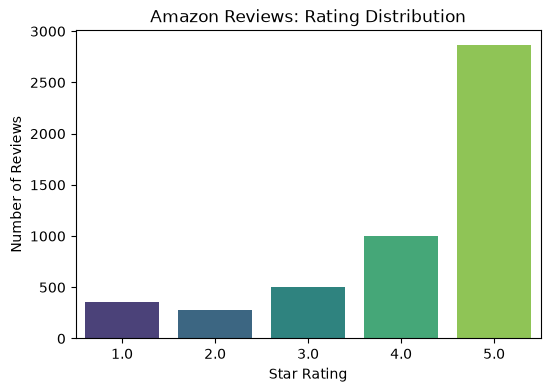

In [50]:
def explore_amazon_data_structure(reviews_df, metadata_df):
    """Explore and display data structure with formatted tables"""
print("\nEXPLORING AMAZON DATA STRUCTURE")
print("=" * 50)

# Dataset sizes
print("\nDataset Sizes")
table = [
["Reviews", reviews_df.shape[0], reviews_df.shape[1]],
["Metadata", metadata_df.shape[0], metadata_df.shape[1]]
]
print(tabulate(table, headers=["Dataset", "Rows", "Columns"],
tablefmt="grid"))

# Column names
print("\nReviews Columns")
print(tabulate([[c] for c in reviews_df.columns], headers=["Column"],
tablefmt="grid"))
print("\nMetadata Columns")
print(tabulate([[c] for c in metadata_df.columns], headers=["Column"],
tablefmt="grid"))

# Sample review
print("\nSample Review")
review_sample = reviews_df.iloc[0].to_dict()
print(tabulate(review_sample.items(), headers=["Field", "Value"],
tablefmt="grid"))
# Sample metadata
print("\nSample Product Metadata")
meta_sample = metadata_df.iloc[0].to_dict()
print(tabulate(meta_sample.items(), headers=["Field", "Value"],
tablefmt="grid"))

# Rating distribution
if "rating" in reviews_df.columns:
    print("\n Rating Distribution")
    rating_counts = reviews_df['rating'].value_counts().sort_index()
    print(tabulate(rating_counts.reset_index().values,
    headers=["Rating", "Count"], tablefmt="grid"))

# Plot
plt.figure(figsize=(6,4))
sns.countplot(x="rating", data=reviews_df, palette="viridis",
order=sorted(reviews_df["rating"].dropna().unique()))
plt.title("Amazon Reviews: Rating Distribution")
plt.xlabel("Star Rating")
plt.ylabel("Number of Reviews")
plt.show()
explore_amazon_data_structure(reviews_df, metadata_df)


Exercide 7 

In [57]:
def ai_amazon_demo(reviews_df, metadata_df, num_reviews=5):
    print("\n AI-POWERED AMAZON REVIEW DEMO")
    print("=" * 55)

    # Candidate labels for zero-shot classifier
    candidate_labels = ["Quality", "Delivery", "Price", "Usability", "Durability"]

    # Pick random reviews
    sample_reviews = reviews_df.dropna(subset=['text']).sample(num_reviews)
    sentiments, categories = [], []
    for i, (_, review) in enumerate(sample_reviews.iterrows(), 1):
        text = str(review['text'])[:300]
        asin = review.get('asin', 'Unknown')
        rating = review.get('rating', 0)
        print(f"\n Review #{i} (Product ID: {asin})")
        print(f" {text}...")

        # ---- Sentiment Analysis ----
        if 'sentiment' in ai_models:
            result = ai_models['sentiment'](text)[0]
            sentiment = result['label']
            score = result['score']
        else:
            sentiment, score = ("POSITIVE" if rating >= 4 else "NEGATIVE",0.9)

        sentiments.append(sentiment)
        print(f" Rating: {rating}")
        print(f" Sentiment: {sentiment} (confidence: {score:.2f})")

        # ---- Classification ----
        if 'classifier' in ai_models:
            classify = ai_models['classifier'](text,
        candidate_labels=candidate_labels)
            top_label = classify['labels'][0]
            cat_score = classify['scores'][0]
        else:
            top_label, cat_score = random.choice(candidate_labels), 0.8
        categories.append(top_label)
        print(f" Key Topic: {top_label} (confidence: {cat_score:.2f})")




In [ ]:
# ---- Text Generation (summary) ----
if 'text_generator' in ai_models:
    prompt = f"Summarize this review in one sentence:\n{text}\nSummary:"
    generated = ai_models['text_generator'](
        prompt, max_new_tokens=50, temperature=0.7,
        pad_token_id=50256
    )[0]['generated_text']
    summary = generated.replace(prompt, "").strip()
else:
    summary = f"This review mainly talks about {top_label.lower()}."

print(f"AI Summary: {summary}")
time.sleep(0.5)

print("\nVISUAL INSIGHTS")
# Sentiment distribution
plt.figure(figsize=(6,4))
sns.countplot(x=sentiments, palette="viridis")
plt.title("Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Count")
plt.show()

ai_amazon_demo(reviews_df, metadata_df)


Done